# HW 6 — Statistical Arbitrage Portfolio Construction

Цель: построить **единый портфель межтоварных mean-reversion стратегий**, а не набор независимых красивых бэктестов.

Основные решения:

1. Из 5-минутных рядов строится дневной непрерывный индекс каждого фьючерса. В день ролла доходность не переносится между разными контрактами — так искусственный roll-gap не становится сигналом.
2. Пары генерируются внутри экономически осмысленных групп. Можно включить полный декартов набор флагом `WITHIN_GROUP_ONLY=False`.
3. Все оценки — walk-forward. На train-окне оцениваются beta и фильтры; следующие `REFIT_EVERY` дней являются OOS, параметры в них заморожены.
4. «Ноль» спреда — предсказанная по прошлому скользящая медиана. Масштаб — rolling MAD. Оба ряда сдвинуты на один бар.
5. Сигнал использует гистерезис: вход далеко от нуля, выход только после устойчивого возврата в узкую зону около нуля.
6. `max_hold` выводится из half-life, а не оптимизируется по прибыли. Kill switch существует отдельно на уровне пары и книги.
7. Стратегии нормируются по ex-ante volatility, затем риск делится между группами. Стоимость портфеля считается после неттинга целевых экспозиций по базовым товарам.

> Ноутбук предназначен для исследования. Параметры лимитов — стартовые консервативные значения, а не инвестиционная рекомендация.

In [1]:
from pathlib import Path
from dataclasses import dataclass, asdict
from itertools import combinations
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

DATA_PATH = Path(r"./data/dfs_5min.pickle")
assert DATA_PATH.exists(), f"Файл не найден: {DATA_PATH}"

CLASS_DICT = {
    "meat": ["LE", "GF", "HE"],
    "grains": ["ZC", "ZS", "ZL", "ZM", "ZW", "KE", "ZO", "ZR"],
    "energy": ["CL", "HO", "RB", "QA", "LF"],
    "sugar": ["SB", "SW"],
}

MULTIPLIER = {
    "LE": 400, "GF": 500, "HE": 400,
    "ZC": 50, "ZS": 50, "ZL": 600, "ZM": 100, "ZW": 50,
    "KE": 50, "ZO": 50, "ZR": 2000,
    "CL": 1000, "HO": 42000, "RB": 42000, "NG": 10000,
    "QA": 1000, "LF": 100, "SB": 1120, "SW": 50,
}

@dataclass(frozen=True)
class Config:
    start: str = "2010-01-01"
    end: str | None = '2015-01-01'

    # Walk-forward
    train_days: int = 360
    refit_every: int = 60

    # Динамический центр spread
    center_window: int = 63
    min_center_obs: int = 30

    # Статистические фильтры
    min_corr: float = 0.35
    max_coint_p: float = 0.05
    max_adf_p: float = 0.05

    # Half-life
    min_half_life: int = 2
    max_half_life: int = 60
    max_hold_mult: float = 3.0
    max_hold_floor: int = 5
    max_hold_cap: int = 90

    # Эмпирические границы гистерезиса
    long_entry_quantile: float = 0.2
    long_exit_quantile: float = 0.40
    short_exit_quantile: float = 0.60
    short_entry_quantile: float = 0.7

    # Очистка IS-распределения для линий гистерезиса
    outlier_mad_limit: float = 5.0
    winsor_lower_quantile: float = 0.005
    winsor_upper_quantile: float = 0.995

    # Stop определяется более экстремальными квантилями
    stop_lower_quantile: float = 0.005
    stop_upper_quantile: float = 0.995

    cooldown_days: int = 200

    # Costs
    cost_bps_per_leg: float = 1.0

    # Portfolio
    annual_target_vol: float = 0.10
    vol_lookback: int = 63
    max_strategy_weight: float = 0.15
    max_group_weight: float = 0.40

    # Book kill switch
    book_daily_loss: float = 0.02
    book_max_drawdown: float = 0.12
    book_recovery_days: int = 10
    min_active_fraction: float = 0.60

CFG = Config()
WITHIN_GROUP_ONLY = True
print(pd.Series(asdict(CFG), name="value"))

start                    2010-01-01
end                      2015-01-01
train_days                      360
refit_every                      60
center_window                    63
min_center_obs                   30
min_corr                       0.35
max_coint_p                    0.05
max_adf_p                      0.05
min_half_life                     2
max_half_life                    60
max_hold_mult                   3.0
max_hold_floor                    5
max_hold_cap                     90
long_entry_quantile             0.2
long_exit_quantile              0.4
short_exit_quantile             0.6
short_entry_quantile            0.7
outlier_mad_limit               5.0
winsor_lower_quantile         0.005
winsor_upper_quantile         0.995
stop_lower_quantile           0.005
stop_upper_quantile           0.995
cooldown_days                   200
cost_bps_per_leg                1.0
annual_target_vol               0.1
vol_lookback                     63
max_strategy_weight         

## 1. Подготовка данных и непрерывные ряды

`OpenInterest` и `SaleCondition` полностью пусты и не используются. В каждом корневом тикере одновременно могут присутствовать разные экспирации. На каждом дне выбираем контракт с максимальным дневным объёмом. Межконтрактный скачок цены не включаем в доходность: первая доходность после смены символа равна нулю. Из очищенных доходностей строим синтетический индекс для статистической оценки; реальные цены активного контракта сохраняем для диагностики и перевода риска в контракты.

In [2]:
dfs = pd.read_pickle(DATA_PATH)
available = set(dfs)
universe = [x for xs in CLASS_DICT.values() for x in xs if x in available]
missing = sorted(set(x for xs in CLASS_DICT.values() for x in xs) - available)
print(f"Доступно серий: {len(dfs)}; используем: {len(universe)}")
print("Universe:", universe)
if missing:
    print("Нет в pickle:", missing)

structure = []
for root in universe:
    d = dfs[root]
    structure.append({
        "root": root, "rows": len(d), "from": d["Date"].min(), "to": d["Date"].max(),
        "symbols": d["Symbol"].nunique(), "empty_columns": [c for c in d if d[c].isna().all()]
    })
pd.DataFrame(structure).set_index("root")

Доступно серий: 35; используем: 18
Universe: ['LE', 'GF', 'HE', 'ZC', 'ZS', 'ZL', 'ZM', 'ZW', 'KE', 'ZO', 'ZR', 'CL', 'HO', 'RB', 'QA', 'LF', 'SB', 'SW']


,rows,from,to,symbols,empty_columns
root,,,,,
LE,339066,2008-05-05 09:05:00,2023-08-10 11:00:00,93,"[OpenInterest, SaleCondition]"
GF,275826,2008-05-05 09:05:00,2023-08-10 11:00:00,117,"[OpenInterest, SaleCondition]"
HE,348686,2008-05-05 09:05:00,2023-08-10 11:00:00,109,"[OpenInterest, SaleCondition]"
ZC,744746,2008-05-04 18:00:00,2023-08-10 11:00:00,66,"[OpenInterest, SaleCondition]"
ZS,764096,2008-05-04 18:00:00,2023-08-10 11:00:00,77,"[OpenInterest, SaleCondition]"
ZL,735005,2008-05-04 20:20:00,2023-08-10 11:00:00,77,"[OpenInterest, SaleCondition]"
ZM,703413,2008-05-04 20:20:00,2023-08-10 11:00:00,77,"[OpenInterest, SaleCondition]"
ZW,724802,2008-05-04 18:00:00,2023-08-10 11:00:00,77,"[OpenInterest, SaleCondition]"
KE,508681,2008-05-04 20:20:00,2023-08-10 11:00:00,78,"[OpenInterest, SaleCondition]"


In [5]:
dfs['ZS']

,Date,Symbol,Open,High,Low,Close,Volume,OpenInterest,SaleCondition
0,2023-08-10 11:00:00,ZSX23,1321.25,1321.50,1319.75,1319.75,382,NaN,NaN
1,2023-08-10 10:55:00,ZSX23,1320.75,1322.50,1320.75,1321.50,269,NaN,NaN
2,2023-08-10 10:50:00,ZSX23,1322.00,1322.00,1319.75,1320.50,446,NaN,NaN
3,2023-08-10 10:45:00,ZSX23,1321.50,1322.25,1320.50,1322.25,320,NaN,NaN
4,2023-08-10 10:40:00,ZSX23,1320.00,1321.50,1319.75,1321.50,173,NaN,NaN
...,...,...,...,...,...,...,...,...,...
764091,2008-05-04 20:20:00,ZSN08,1298.50,1310.00,1284.25,1302.00,20,NaN,NaN
764092,2008-05-04 18:55:00,ZSN08,1292.50,1292.50,1286.00,1288.00,1,NaN,NaN
764093,2008-05-04 18:30:00,ZSN08,1295.50,1295.50,1292.50,1292.50,1,NaN,NaN
764094,2008-05-04 18:10:00,ZSN08,1294.00,1295.75,1293.25,1295.00,1,NaN,NaN


In [6]:
df = dfs["ZS"].copy()
df["Date"] = pd.to_datetime(df["Date"])

contracts_per_day = (
    df.assign(day=df["Date"].dt.date)
      .groupby("day")["Symbol"]
      .nunique()
)

contracts_per_day.describe()

count    4636.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: Symbol, dtype: float64

In [7]:
df.loc[
    df["Date"].dt.date == pd.Timestamp("2023-08-10").date(),
    "Symbol"
].value_counts()

Symbol
ZSX23    124
Name: count, dtype: int64

<Axes: xlabel='Date', ylabel='Close'>

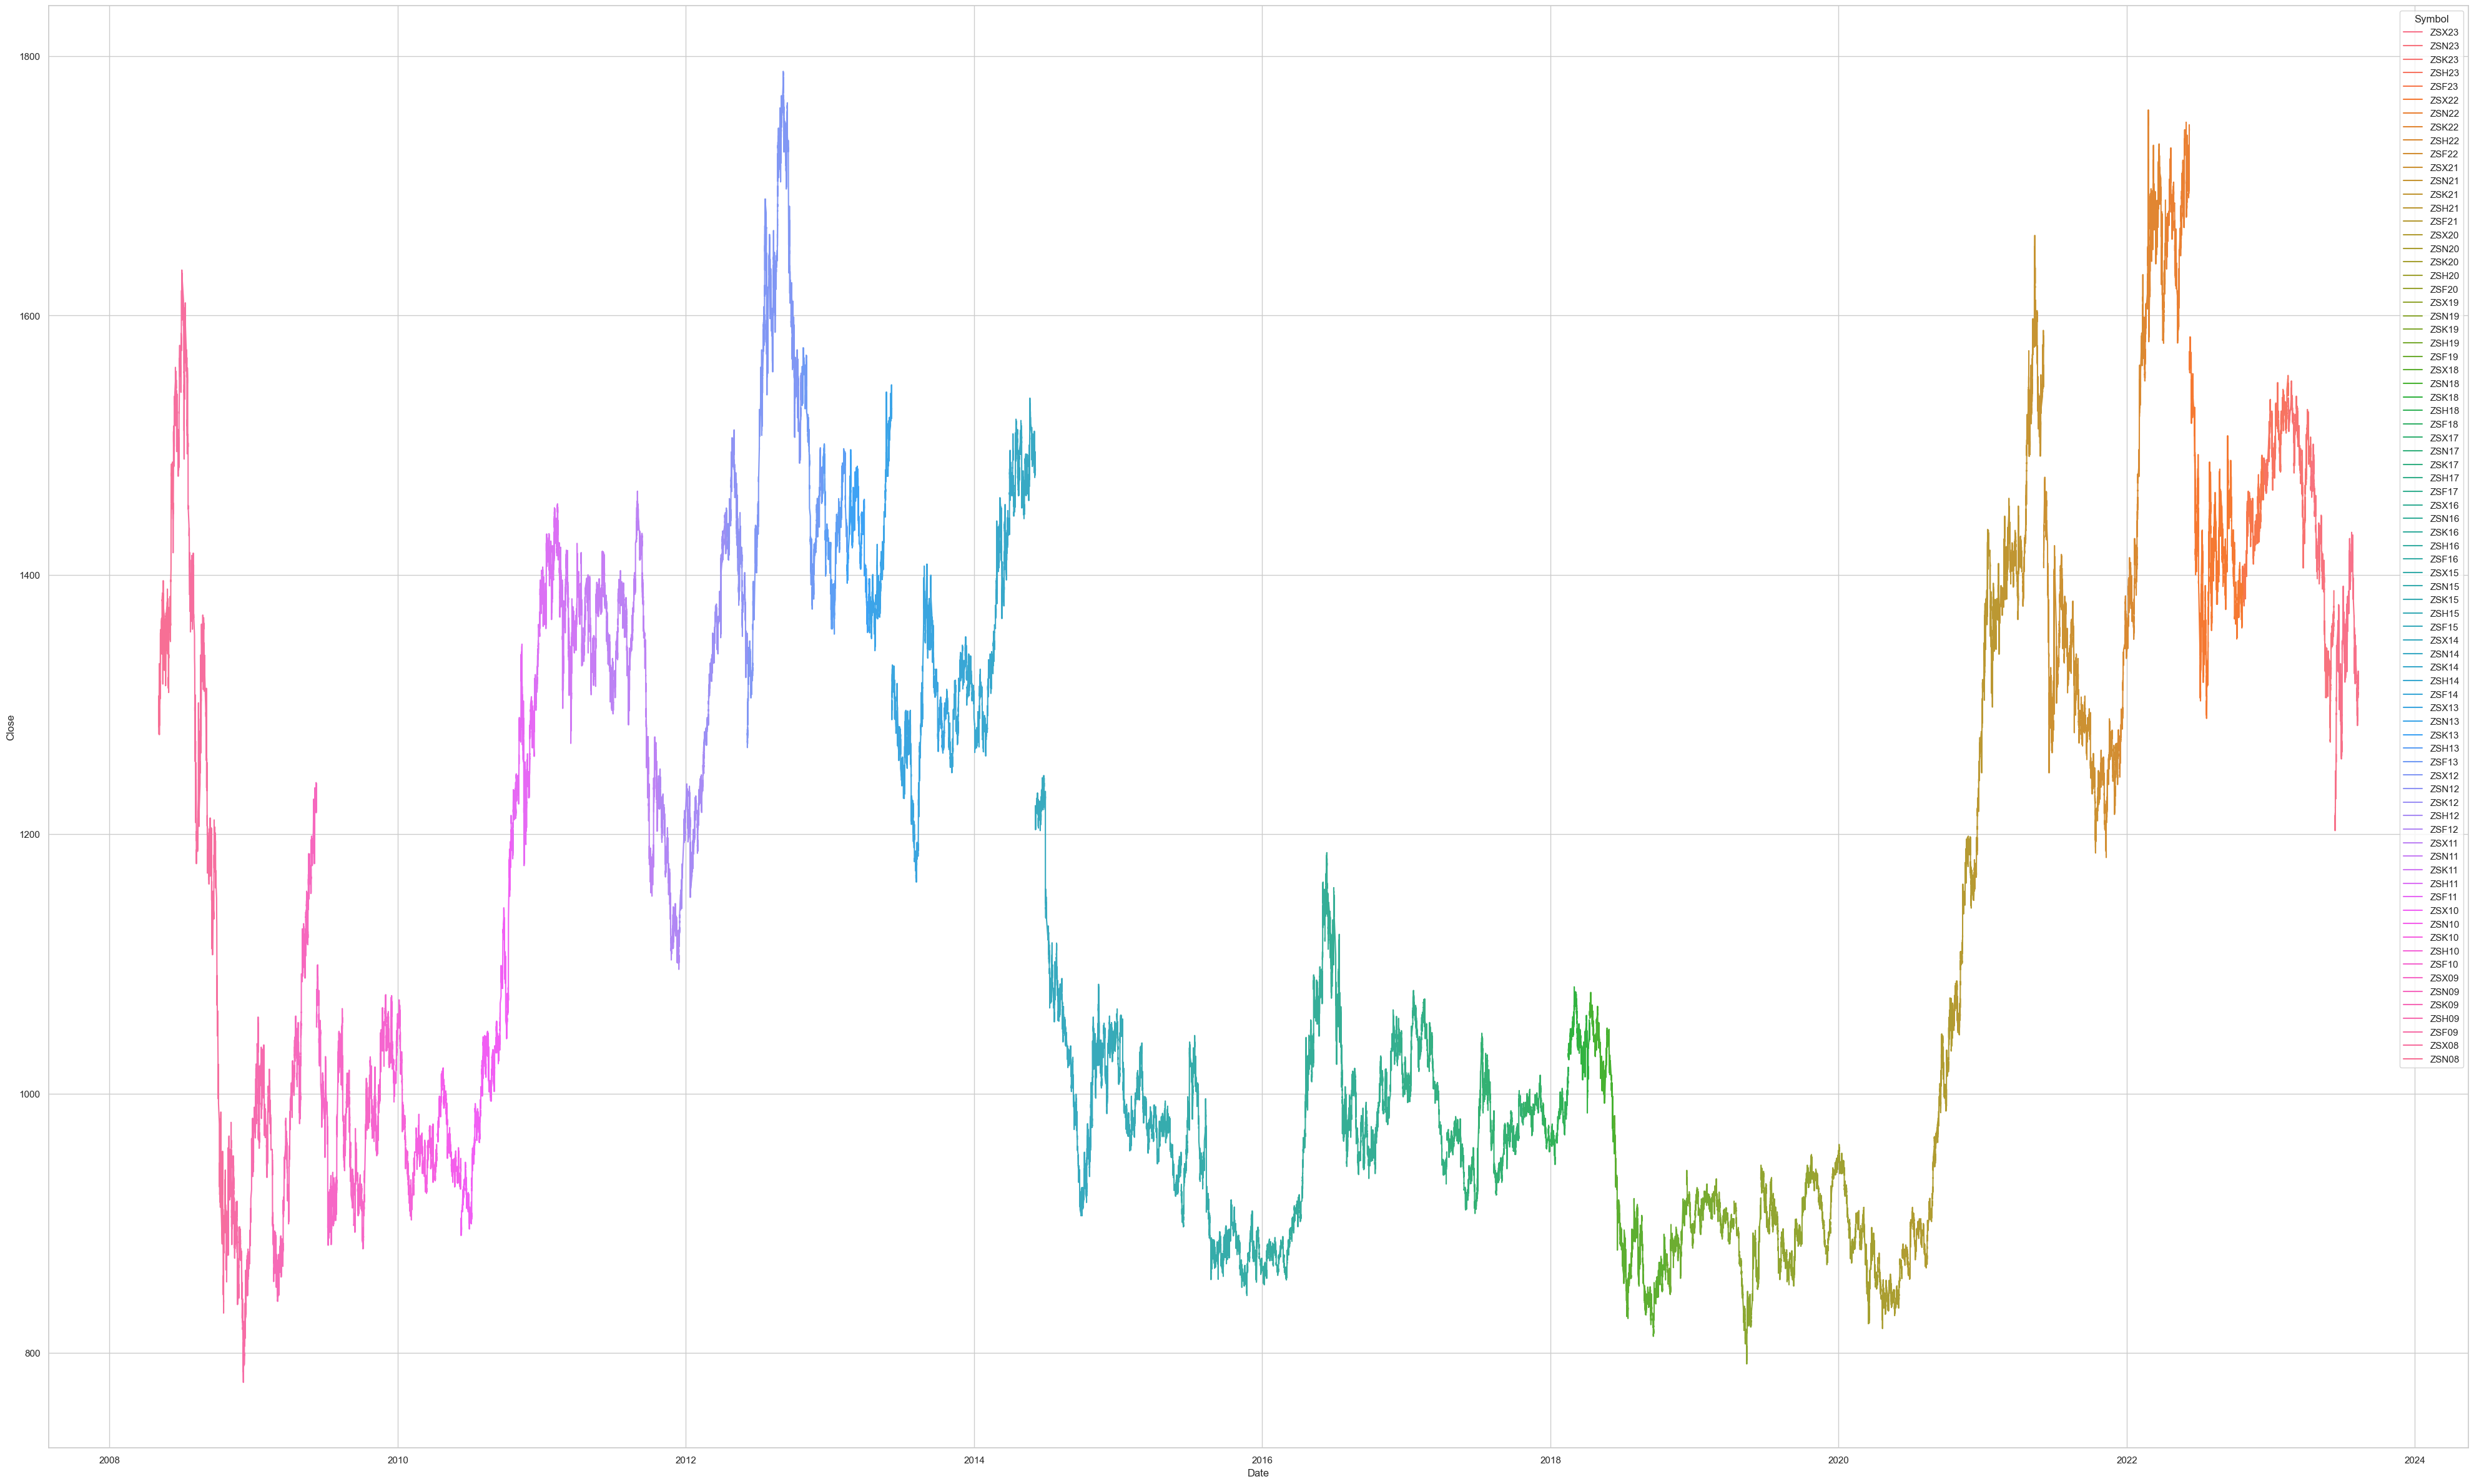

In [10]:
plt.figure(figsize=(50, 30))
sns.lineplot(dfs['ZS'], x='Date', y='Close', hue='Symbol')

In [265]:
def make_daily_continuous(raw: pd.DataFrame) -> pd.DataFrame:
    d = raw.loc[:, ["Date", "Symbol", "Close", "Volume"]].dropna(subset=["Date", "Symbol", "Close"]).copy()
    d = d.sort_values("Date")
    d["day"] = d["Date"].dt.normalize()
    daily_volume = d.groupby(["day", "Symbol"], observed=True)["Volume"].sum()
    active = daily_volume.groupby(level=0).idxmax().map(lambda x: x[1]).rename("active_symbol")
    d = d.join(active, on="day")
    d = d[d["Symbol"].eq(d["active_symbol"])]
    out = d.groupby("day", observed=True).agg(
        close=("Close", "last"), volume=("Volume", "sum"), symbol=("Symbol", "last")
    )
    same_contract = out["symbol"].eq(out["symbol"].shift())
    out["log_return"] = np.log(out["close"]).diff().where(same_contract, 0.0).replace([np.inf, -np.inf], np.nan)
    out["synthetic_log"] = out["log_return"].fillna(0.0).cumsum()
    return out

daily = {root: make_daily_continuous(dfs[root]) for root in universe}
del dfs

log_price = pd.concat({k: v["synthetic_log"] for k, v in daily.items()}, axis=1).sort_index()
returns = pd.concat({k: v["log_return"] for k, v in daily.items()}, axis=1).reindex(log_price.index)
active_close = pd.concat({k: v["close"] for k, v in daily.items()}, axis=1).reindex(log_price.index)
active_symbol = pd.concat({k: v["symbol"] for k, v in daily.items()}, axis=1).reindex(log_price.index)

mask = log_price.index >= pd.Timestamp(CFG.start)
if CFG.end is not None:
    mask &= log_price.index <= pd.Timestamp(CFG.end)
log_price, returns, active_close, active_symbol = [x.loc[mask] for x in (log_price, returns, active_close, active_symbol)]

print("Период:", log_price.index.min().date(), "—", log_price.index.max().date())
print("Размер панели:", log_price.shape)
log_price.notna().mean().sort_values().to_frame("coverage")

Период: 2010-01-03 — 2015-01-01
Размер панели: (1558, 18)


,coverage
SW,0.584724
QA,0.693838
SB,0.808087
LE,0.815148
HE,0.815148
GF,0.815148
ZR,0.969191
ZO,0.974968
ZW,0.975610
ZM,0.975610


## 2. Кандидаты и walk-forward фильтры

Для каждой пары на train-окне:

- OLS: `log_index_A = alpha + beta * log_index_B`;
- корреляция дневных доходностей;
- Engle–Granger и ADF остатка;
- half-life из `Δspread_t = a + λ spread_{t-1} + ε_t`.

Пара допускается в следующий OOS-блок только если beta положительна, связь достаточно сильна, оба теста проходят, а half-life находится в разумном диапазоне. Это предотвращает selection look-ahead: OOS результат не участвует в выборе.

In [266]:
def candidate_pairs(columns, within_group_only=True):
    columns = set(columns)
    if within_group_only:
        out = []
        for group, names in CLASS_DICT.items():
            valid = [x for x in names if x in columns]
            out.extend((a, b, group) for a, b in combinations(valid, 2))
        return out
    group_of = {x: g for g, xs in CLASS_DICT.items() for x in xs}
    return [(a, b, group_of.get(a, "other") if group_of.get(a) == group_of.get(b) else "cross")
            for a, b in combinations(sorted(columns), 2)]

def estimate_half_life_no_intercept(
    spread: pd.Series,
) -> float:
    """
    Оценивает:
        Δspread_t = lambda * spread_(t-1) + error_t

    Константа отсутствует, поскольку spread строится
    при ограничении alpha = 0.
    """
    spread = (
        spread
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if len(spread) < 50:
        return np.nan

    regression_data = pd.DataFrame({
        "delta": spread.diff(),
        "lag": spread.shift(1),
    }).dropna()

    if len(regression_data) < 30:
        return np.nan

    model = sm.OLS(
        regression_data["delta"],
        regression_data[["lag"]],
    ).fit()

    lambda_coefficient = model.params["lag"]

    if (
        not np.isfinite(lambda_coefficient)
        or lambda_coefficient >= 0
    ):
        return np.inf

    return float(
        -np.log(2) / lambda_coefficient
    )

def fit_pair(
    train: pd.DataFrame,
    a: str,
    b: str,
) -> dict:
    """
    Оценка параметров пары только на текущем train-окне.

    Модель:
        indexed_A_t = beta * indexed_B_t + spread_t

    alpha фиксирована на нуле.
    """
    prices = (
        train[[a, b]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .copy()
    )

    pair_returns = (
        returns.loc[prices.index, [a, b]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    min_required_observations = int(
        CFG.train_days * 0.75
    )

    if (
        len(prices) < min_required_observations
        or len(pair_returns) < 100
    ):
        return {
            "pass": False,
            "reason": "history",
            "alpha": 0.0,
        }

    # -----------------------------------------------
    # Единая точка отсчёта текущего train/OOS блока
    # -----------------------------------------------

    base_date = prices.index[0]

    base_a = float(prices.at[base_date, a])
    base_b = float(prices.at[base_date, b])

    indexed_a = prices[a] - base_a
    indexed_b = prices[b] - base_b

    # Первая строка содержит два нуля и не нужна для OLS
    regression_data = pd.DataFrame({
        "A": indexed_a,
        "B": indexed_b,
    }).iloc[1:].dropna()

    denominator = np.dot(
        regression_data["B"],
        regression_data["B"],
    )

    if (
        not np.isfinite(denominator)
        or denominator <= 1e-12
    ):
        return {
            "pass": False,
            "reason": "degenerate_regressor",
            "alpha": 0.0,
            "base_date": base_date,
            "base_a": base_a,
            "base_b": base_b,
        }

    # OLS без константы:
    # beta = sum(A_t * B_t) / sum(B_t^2)
    beta = (
        np.dot(
            regression_data["B"],
            regression_data["A"],
        )
        / denominator
    )

    if not np.isfinite(beta):
        return {
            "pass": False,
            "reason": "invalid_beta",
            "alpha": 0.0,
            "beta": beta,
            "base_date": base_date,
            "base_a": base_a,
            "base_b": base_b,
        }

    spread = (
        indexed_a
        - beta * indexed_b
    )

    # Корреляция доходностей
    corr = pair_returns[a].corr(
        pair_returns[b]
    )

    # Cointegration test без deterministic intercept
    try:
        coint_stat, coint_p, _ = coint(
            indexed_a,
            indexed_b,
            trend="n",
            autolag="aic",
        )
    except Exception:
        coint_stat = np.nan
        coint_p = 1.0

    # ADF остатка без константы
    try:
        adf_result = adfuller(
            spread.dropna(),
            regression="n",
            autolag="AIC",
        )

        adf_stat = adf_result[0]
        adf_p = adf_result[1]

    except Exception:
        adf_stat = np.nan
        adf_p = 1.0

    hl = estimate_half_life_no_intercept(
        spread
    )

    if np.isfinite(hl):
        max_hold = int(
            np.clip(
                np.ceil(
                    CFG.max_hold_mult * hl
                ),
                CFG.max_hold_floor,
                CFG.max_hold_cap,
            )
        )
    else:
        max_hold = CFG.max_hold_cap

    checks = {
        "positive_beta": (
            np.isfinite(beta)
            and beta > 0
        ),
        "correlation": (
            np.isfinite(corr)
            and corr >= CFG.min_corr
        ),
        "cointegration": (
            np.isfinite(coint_p)
            and coint_p <= CFG.max_coint_p
        ),
        "stationarity": (
            np.isfinite(adf_p)
            and adf_p <= CFG.max_adf_p
        ),
        "half_life": (
            np.isfinite(hl)
            and CFG.min_half_life
            <= hl
            <= CFG.max_half_life
        ),
    }

    passed = all(checks.values())

    failed_checks = [
        name
        for name, result in checks.items()
        if not result
    ]

    return {
        "pass": passed,
        "reason": (
            "ok"
            if passed
            else ", ".join(failed_checks)
        ),

        "alpha": 0.0,
        "beta": beta,

        # База нужна для согласованного OOS spread
        "base_date": base_date,
        "base_a": base_a,
        "base_b": base_b,

        "corr": corr,

        "coint_stat": coint_stat,
        "coint_p": coint_p,

        "adf_stat": adf_stat,
        "adf_p": adf_p,

        "half_life": hl,
        "max_hold": max_hold,

        **{
            f"check_{name}": result
            for name, result in checks.items()
        },
    }

pairs = candidate_pairs(log_price.columns, WITHIN_GROUP_ONLY)
print(f"Кандидатов: {len(pairs)}")
pd.DataFrame(pairs, columns=["A", "B", "group"]).groupby("group").size().rename("pairs")

Кандидатов: 42


group
energy    10
grains    28
meat       3
sugar      1
Name: pairs, dtype: int64

## 3. Сигнал: динамический ноль, MAD и гистерезис

Пусть `spread_t = log(A_t) − alpha − beta·log(B_t)`.

- `zero_t = mean(spread_{t-W}, …, spread_{t-1})`;
- `scale_t = 1.4826 · mean(|spread − zero|)` по прошлому окну;
- `z_t = (spread_t − zero_t) / scale_t`.

Сдвиг на один день обязателен: сегодняшний close ещё нельзя использовать для сегодняшнего исполнения. Позиция, рассчитанная по `z_t`, применяется к доходности `t+1`.

Гистерезис:

- flat → long spread при `z ≤ −entry_z`, flat → short при `z ≥ entry_z`;
- long закрывается только при `z ≥ −exit_z`, short — при `z ≤ exit_z`;
- stop/kill при экстремальном `|z|`, нарушении pair drawdown или плохих данных;
- после kill действует cooldown; повторный вход в тот же день запрещён.

In [267]:
def robust_zscore(
    spread: pd.Series,
) -> pd.DataFrame:
    """
    Динамический ноль и масштаб оцениваются
    только по предыдущим наблюдениям.
    """
    historical_spread = spread.shift(1)

    center = (
        historical_spread
        .rolling(
            CFG.center_window,
            min_periods=CFG.min_center_obs,
        )
        .median()
    )

    absolute_deviation = (
        historical_spread - center
    ).abs()

    mad = (
        absolute_deviation
        .rolling(
            CFG.center_window,
            min_periods=CFG.min_center_obs,
        )
        .median()
    )

    scale = (
        1.4826 * mad
    ).replace(0, np.nan)

    z = (
        spread - center
    ) / scale

    return pd.DataFrame({
        "spread": spread,
        "zero": center,
        "scale": scale,
        "z": z,
    })

def clean_z_for_hysteresis(
    z_train: pd.Series,
) -> pd.Series:
    """
    Очищает IS z-score для оценки эмпирического
    распределения и линий гистерезиса.

    Торговый временной ряд не изменяется.
    """
    z_train = (
        z_train
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .copy()
    )

    if len(z_train) < 100:
        return pd.Series(dtype=float)

    center = z_train.median()

    mad = (
        z_train - center
    ).abs().median()

    if (
        np.isfinite(mad)
        and mad > 0
    ):
        robust_distance = (
            (z_train - center).abs()
            / (1.4826 * mad)
        )

        z_clean = z_train[
            robust_distance
            <= CFG.outlier_mad_limit
        ].copy()

    else:
        z_clean = z_train.copy()

    if len(z_clean) < 100:
        return pd.Series(dtype=float)

    # Winsorization после удаления грубых выбросов
    lower = z_clean.quantile(
        CFG.winsor_lower_quantile
    )

    upper = z_clean.quantile(
        CFG.winsor_upper_quantile
    )

    return (
        z_clean
        .clip(lower=lower, upper=upper)
        .sort_values()
    )

def fit_hysteresis_parameters(
    z_train: pd.Series,
) -> dict | None:
    """
    Оценивает проекции эмпирических линий
    гистерезиса по очищенному train-распределению.
    """
    z_clean = clean_z_for_hysteresis(
        z_train
    )

    if len(z_clean) < 100:
        return None

    parameters = {
        "long_entry": float(
            z_clean.quantile(
                CFG.long_entry_quantile
            )
        ),

        "long_exit": float(
            z_clean.quantile(
                CFG.long_exit_quantile
            )
        ),

        "short_exit": float(
            z_clean.quantile(
                CFG.short_exit_quantile
            )
        ),

        "short_entry": float(
            z_clean.quantile(
                CFG.short_entry_quantile
            )
        ),

        "stop_long": float(
            z_clean.quantile(
                CFG.stop_lower_quantile
            )
        ),

        "stop_short": float(
            z_clean.quantile(
                CFG.stop_upper_quantile
            )
        ),

        "clean_sample": z_clean,
    }

    valid_order = (
        parameters["stop_long"]
        <= parameters["long_entry"]
        < parameters["long_exit"]
        < parameters["short_exit"]
        < parameters["short_entry"]
        <= parameters["stop_short"]
    )

    if not valid_order:
        return None

    return parameters

def empirical_position_curve(
    x: np.ndarray,
    sorted_sample: np.ndarray,
) -> np.ndarray:
    """
    F(z) переводится в mean-reversion position:

        position(z) = 1 - 2 * F(z)

    Нижний хвост -> long.
    Верхний хвост -> short.
    """
    cdf = (
        np.searchsorted(
            sorted_sample,
            x,
            side="right",
        )
        / len(sorted_sample)
    )

    return 1.0 - 2.0 * cdf

def build_hysteresis_curves(
    parameters: dict,
    n_points: int = 500,
) -> pd.DataFrame:
    sample = np.asarray(
        parameters["clean_sample"],
        dtype=float,
    )

    x_min = np.quantile(sample, 0.001)
    x_max = np.quantile(sample, 0.999)

    z_grid = np.linspace(
        x_min,
        x_max,
        n_points,
    )

    long_gap = (
        parameters["long_exit"]
        - parameters["long_entry"]
    )

    short_gap = (
        parameters["short_entry"]
        - parameters["short_exit"]
    )

    hysteresis_width = max(
        0.5 * (long_gap + short_gap),
        0.05,
    )

    # При падении z система движется по одной ветви,
    # при росте — по другой.
    falling_branch = empirical_position_curve(
        z_grid + hysteresis_width / 2,
        sample,
    )

    rising_branch = empirical_position_curve(
        z_grid - hysteresis_width / 2,
        sample,
    )

    return pd.DataFrame({
        "z": z_grid,
        "falling_branch": falling_branch,
        "rising_branch": rising_branch,
    })

def hysteresis_positions(
    z: pd.Series,
    parameters: dict,
    max_hold: int,
) -> pd.DataFrame:
    """
    Дискретная реализация эмпирической петли:

        0  = flat
        +1 = long spread
        -1 = short spread
    """
    FLAT = 0
    LONG = 1
    SHORT = -1

    state = FLAT
    age = 0
    cooldown = 0

    rows = []

    for dt, value in z.items():
        event = ""

        if cooldown > 0:
            cooldown -= 1

        # -----------------------------
        # Data kill
        # -----------------------------

        if not np.isfinite(value):
            if state != FLAT:
                event = "data_kill"

            state = FLAT
            age = 0

            cooldown = max(
                cooldown,
                CFG.cooldown_days,
            )

        # -----------------------------
        # Flat: ищем вход
        # -----------------------------

        elif state == FLAT:
            age = 0

            if cooldown == 0:
                if value <= parameters["long_entry"]:
                    state = LONG
                    age = 1
                    event = "enter_long"

                elif value >= parameters["short_entry"]:
                    state = SHORT
                    age = 1
                    event = "enter_short"

        # -----------------------------
        # Long spread
        # -----------------------------

        elif state == LONG:
            age += 1

            if value <= parameters["stop_long"]:
                state = FLAT
                age = 0
                cooldown = CFG.cooldown_days
                event = "stop_long"

            elif value >= parameters["long_exit"]:
                state = FLAT
                age = 0
                event = "exit_long"

            elif age >= max_hold:
                state = FLAT
                age = 0
                event = "max_hold_long"

        # -----------------------------
        # Short spread
        # -----------------------------

        elif state == SHORT:
            age += 1

            if value >= parameters["stop_short"]:
                state = FLAT
                age = 0
                cooldown = CFG.cooldown_days
                event = "stop_short"

            elif value <= parameters["short_exit"]:
                state = FLAT
                age = 0
                event = "exit_short"

            elif age >= max_hold:
                state = FLAT
                age = 0
                event = "max_hold_short"

        rows.append({
            "Date": dt,
            "signal_position": state,
            "age": age,
            "cooldown": cooldown,
            "event": event,
        })

    return (
        pd.DataFrame(rows)
        .set_index("Date")
    )

def pair_oos_block(
    a: str,
    b: str,
    group: str,
    train: pd.DataFrame,
    test: pd.DataFrame,
    fit: dict,
):
    beta = fit["beta"]

    base_a = fit["base_a"]
    base_b = fit["base_b"]

    # Добавляем train-хвост для rolling mean/MAD
    combined = pd.concat([
        train,
        test,
    ])

    # Та же индексация, на которой оценивалась beta
    indexed_a = (
        combined[a] - base_a
    )

    indexed_b = (
        combined[b] - base_b
    )

    spread = (
        indexed_a
        - beta * indexed_b
    )

    signal_data = robust_zscore(
        spread
    )

    # --------------------------------------
    # Гистерезис оценивается только на train
    # --------------------------------------

    z_train = signal_data.loc[
        train.index,
        "z",
    ]

    hysteresis_parameters = (
        fit_hysteresis_parameters(z_train)
    )

    if hysteresis_parameters is None:
        return None

    # OOS-сигнал
    oos_signal_data = signal_data.loc[
        test.index
    ]

    state = hysteresis_positions(
        z=oos_signal_data["z"],
        parameters=hysteresis_parameters,
        max_hold=fit["max_hold"],
    )

    # Сигнал close t используется только с t+1
    position = (
        state["signal_position"]
        .shift(1)
        .fillna(0.0)
    )

    return_a = (
        returns.loc[test.index, a]
        .fillna(0.0)
    )

    return_b = (
        returns.loc[test.index, b]
        .fillna(0.0)
    )

    denominator = (
        1.0 + abs(beta)
    )

    leg_a = (
        position / denominator
    )

    leg_b = (
        -position
        * beta
        / denominator
    )

    gross_return = (
        leg_a * return_a
        + leg_b * return_b
    )

    # Turnover и costs считаются отдельно для ног
    turnover_a = (
        leg_a.diff()
        .abs()
        .fillna(leg_a.abs())
    )

    turnover_b = (
        leg_b.diff()
        .abs()
        .fillna(leg_b.abs())
    )

    turnover = (
        turnover_a + turnover_b
    )

    costs = (
        turnover
        * CFG.cost_bps_per_leg
        / 10_000.0
    )

    net_return = (
        gross_return - costs
    )

    result = pd.DataFrame({
        "gross": gross_return,
        "cost": costs,
        "net": net_return,

        "position": position,

        "z": oos_signal_data["z"],
        "zero": oos_signal_data["zero"],
        "spread": oos_signal_data["spread"],

        "event": state["event"],

        "beta": beta,
        "max_hold": fit["max_hold"],

        "leg_A": leg_a,
        "leg_B": leg_b,

        # Сохраняем границы конкретного refit-блока
        "long_entry": (
            hysteresis_parameters["long_entry"]
        ),
        "long_exit": (
            hysteresis_parameters["long_exit"]
        ),
        "short_exit": (
            hysteresis_parameters["short_exit"]
        ),
        "short_entry": (
            hysteresis_parameters["short_entry"]
        ),
        "stop_long": (
            hysteresis_parameters["stop_long"]
        ),
        "stop_short": (
            hysteresis_parameters["stop_short"]
        ),
    })

    return result

## 4. Walk-forward запуск

Каждые `REFIT_EVERY=90` торговых дней модель переоценивается на последних двух годах. Внутри OOS-блока beta и решение «торговать/не торговать» не меняются. Это одновременно реализует требуемую квартальную переоценку и честное разделение train/validation.

In [268]:
all_blocks = []
selection_rows = []
dates = log_price.index

for test_start in range(CFG.train_days, len(dates), CFG.refit_every):
    train_idx = dates[test_start - CFG.train_days:test_start]
    test_idx = dates[test_start:min(test_start + CFG.refit_every, len(dates))]

    train = log_price.loc[train_idx]
    test = log_price.loc[test_idx]

    for a, b, group in pairs:
        fit = fit_pair(train, a, b)

        selection_rows.append({
            "refit_date": test_idx[0],
            "pair": f"{a}/{b}",
            "group": group,
            **fit,
        })

        if fit.get("pass", False):
            out = pair_oos_block(
                a=a,
                b=b,
                group=group,
                train=train,
                test=test,
                fit=fit,
            )

            if out is not None:
                out["pair"] = f"{a}/{b}"
                out["group"] = group
                out["A"] = a
                out["B"] = b

                all_blocks.append(
                    out.reset_index(names="Date")
                )

selection = pd.DataFrame(selection_rows)

if not all_blocks:
    raise RuntimeError(
        "Ни одна пара не прошла фильтры или для прошедших "
        "пар не удалось оценить эмпирический гистерезис."
    )

pair_panel = (
    pd.concat(all_blocks, ignore_index=True)
    .set_index(["Date", "pair"])
    .sort_index()
)

print(
    "Прошло уникальных пар:",
    pair_panel.index.get_level_values("pair").nunique(),
)

print(
    "Среднее число допущенных пар на refit:",
    selection.groupby("refit_date")["pass"].sum().mean().round(1),
)

display(
    selection.loc[selection["pass"]]
    .groupby("pair")
    .agg(
        refits=("pass", "size"),
        beta=("beta", "mean"),
        corr=("corr", "mean"),
        coint_p=("coint_p", "mean"),
        adf_p=("adf_p", "mean"),
        half_life=("half_life", "mean"),
        max_hold=("max_hold", "mean"),
    )
    .sort_values(["refits", "coint_p"], ascending=[False, True])
    .head(20)
)


Прошло уникальных пар: 14
Среднее число допущенных пар на refit: 1.0


,refits,beta,corr,coint_p,adf_p,half_life,max_hold
pair,,,,,,,
ZW/ZO,5,0.875762,0.583256,0.024275,0.002443,18.197720,55.00
ZS/ZM,4,0.782636,0.923037,0.009286,0.000896,17.238114,52.25
ZL/ZO,1,0.521748,0.474813,0.009953,0.000835,12.842258,39.00
ZS/ZO,1,0.863840,0.465014,0.017265,0.001573,14.462152,44.00
ZL/ZM,1,1.825823,0.642403,0.017940,0.001645,12.300257,37.00
ZL/KE,1,0.371322,0.614267,0.029849,0.002997,12.805500,39.00
CL/LF,1,0.579983,0.834927,0.032867,0.003363,15.266724,46.00
ZC/ZS,1,0.402165,0.630070,0.035199,0.003652,13.701063,42.00
ZC/KE,1,0.104645,0.784572,0.038926,0.004125,15.049246,46.00


In [269]:
check_columns = [
    "check_positive_beta",
    "check_correlation",
    "check_cointegration",
    "check_stationarity",
    "check_half_life",
]

available_check_columns = [
    column
    for column in check_columns
    if column in selection.columns
]

filter_diagnostics = pd.DataFrame({
    "passed": (
        selection[available_check_columns]
        .fillna(False)
        .sum()
    ),
    "failed": (
        ~selection[available_check_columns]
        .fillna(False)
    ).sum(),
})

filter_diagnostics["passed_fraction"] = (
    filter_diagnostics["passed"]
    / len(selection)
)

display(filter_diagnostics)

display(
    selection["reason"]
    .value_counts()
    .to_frame("count")
    .head(20)
)

,passed,failed,passed_fraction
check_positive_beta,617,223,0.734524
check_correlation,564,276,0.671429
check_cointegration,38,802,0.045238
check_stationarity,189,651,0.225000
check_half_life,404,436,0.480952


,count
reason,
"cointegration, stationarity, half_life",237
"cointegration, stationarity",138
cointegration,100
history,63
"correlation, cointegration, stationarity, half_life",55
"positive_beta, correlation, cointegration, stationarity, half_life",53
"correlation, cointegration, stationarity",30
"positive_beta, cointegration, stationarity, half_life",28
"positive_beta, cointegration, stationarity",26


## 4.1. Проверка `pair_panel` и визуализация гистерезиса


In [270]:
required_pair_panel_columns = {
    "gross", "cost", "net", "position", "z", "zero", "spread",
    "event", "beta", "max_hold", "leg_A", "leg_B",
    "long_entry", "long_exit", "short_exit", "short_entry",
    "stop_long", "stop_short", "group", "A", "B",
}

missing_pair_panel_columns = (
    required_pair_panel_columns - set(pair_panel.columns)
)

if missing_pair_panel_columns:
    raise KeyError(
        "В pair_panel отсутствуют колонки: "
        f"{sorted(missing_pair_panel_columns)}"
    )

selected_pairs = (
    pair_panel.index
    .get_level_values("pair")
    .unique()
    .tolist()
)

print("Колонки pair_panel:", pair_panel.columns.tolist())
print("Пары для графиков:", selected_pairs)
display(pair_panel.head())


Колонки pair_panel: ['gross', 'cost', 'net', 'position', 'z', 'zero', 'spread', 'event', 'beta', 'max_hold', 'leg_A', 'leg_B', 'long_entry', 'long_exit', 'short_exit', 'short_entry', 'stop_long', 'stop_short', 'group', 'A', 'B']
Пары для графиков: ['ZW/KE', 'ZW/ZO', 'CL/LF', 'ZL/ZM', 'ZS/ZM', 'ZL/KE', 'ZC/KE', 'ZC/ZL', 'ZC/ZS', 'ZC/ZW', 'ZL/ZO', 'LE/HE', 'ZS/ZO', 'LE/GF']


gross    cost       net  position         z      zero    spread        event      beta  max_hold    leg_A    leg_B  long_entry  \
Date       pair                                                                                                                                       
2011-05-10 ZW/KE  0.000000  0.0000  0.000000       0.0 -0.055990 -0.068005 -0.071130               0.436669        64  0.00000 -0.00000   -1.481186   
           ZW/ZO  0.000000  0.0000  0.000000       0.0  0.479277 -0.025809 -0.003169  enter_short  0.348817        53  0.00000 -0.00000   -0.960372   
2011-05-11 ZW/KE  0.000000  0.0000  0.000000       0.0 -0.712337 -0.068247 -0.107900               0.436669        64  0.00000 -0.00000   -1.481186   
           ZW/ZO  0.030399  0.0001  0.030299      -1.0 -0.388728 -0.025809 -0.044172   exit_short  0.348817        53 -0.74139  0.25861   -0.960372   
2011-05-12 ZW/KE  0.000000  0.0000  0.000000       0.0 -1.069530 -0.068307 -0.127985               0.436669        64  0.00000 -0.00000   -1.481186   

                  long_exit  short_exit  short_entry  stop_long  stop_short   group   A   B  
Date       pair                                                                              
2011-05-10 ZW/KE  -0.592199    0.031614     0.313512  -3.280367    2.560950  grains  ZW  KE  
           ZW/ZO  -0.408356    0.125891     0.333261  -2.883700    1.784679  grains  ZW  ZO  
2011-05-11 ZW/KE  -0.592199    0.031614     0.313512  -3.280367    2.560950  grains  ZW  KE  
           ZW/ZO  -0.408356    0.125891     0.333261  -2.883700    1.784679  grains  ZW  ZO  
2011-05-12 ZW/KE  -0.592199    0.031614     0.313512  -3.280367    2.560950  grains  ZW  KE

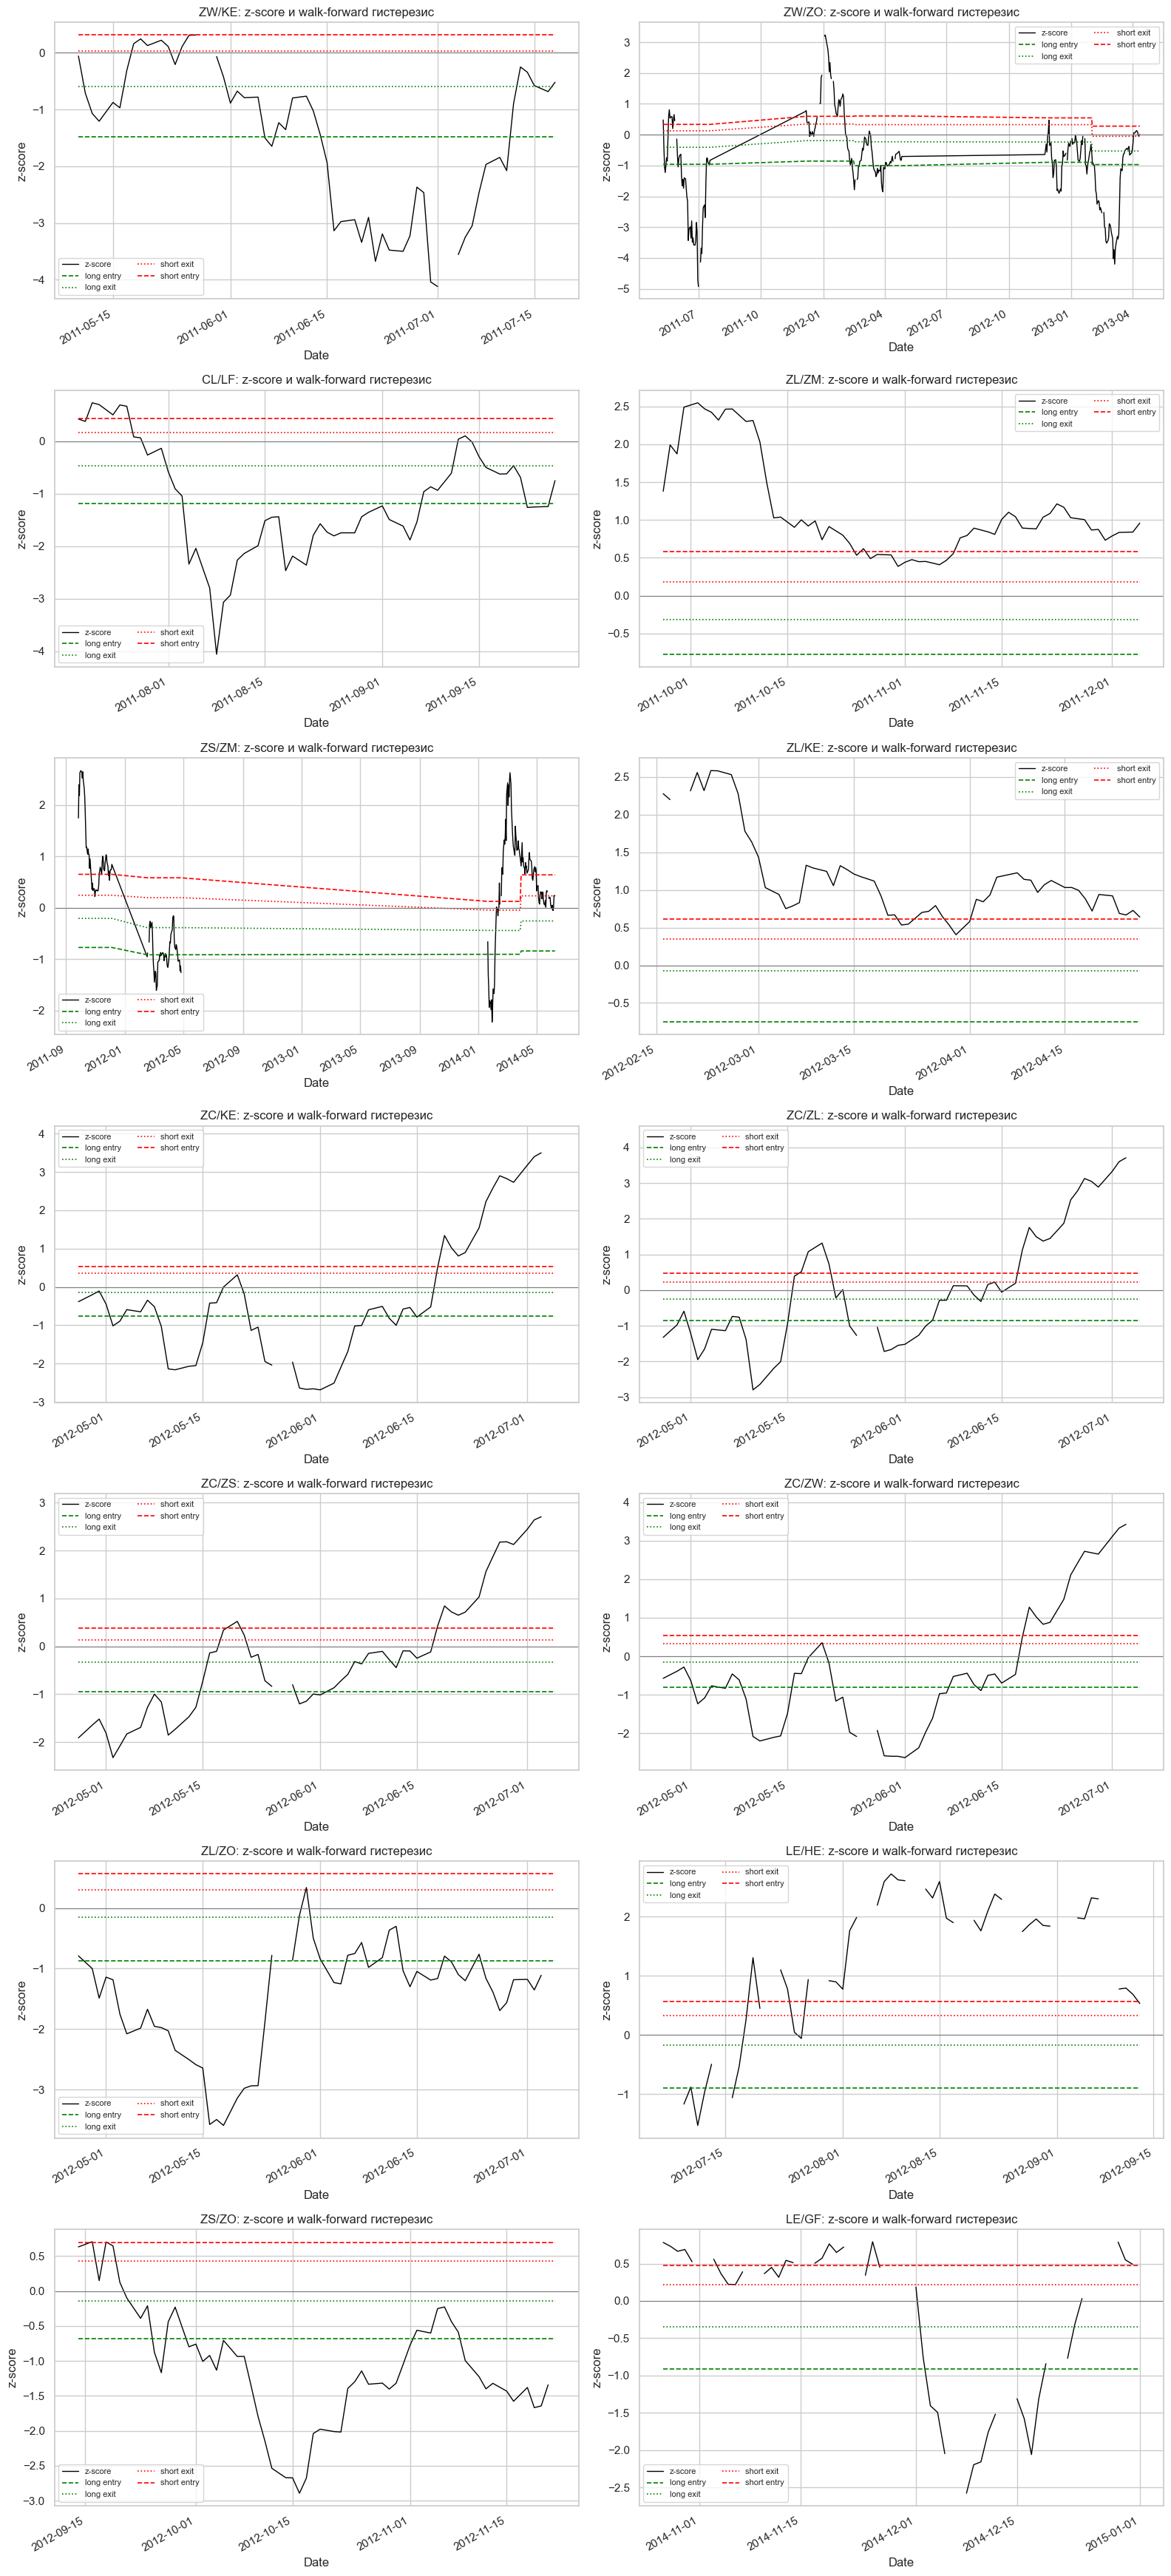

In [271]:
n_pairs = len(selected_pairs)

if n_pairs == 0:
    print("Нет пар для построения графиков.")
else:
    n_columns = 2
    n_rows = int(np.ceil(n_pairs / n_columns))

    fig, axes = plt.subplots(
        n_rows,
        n_columns,
        figsize=(16, 5 * n_rows),
        squeeze=False,
    )

    axes = axes.ravel()

    for ax, pair in zip(axes, selected_pairs):
        pair_data = (
            pair_panel
            .xs(pair, level="pair")
            .sort_index()
        )

        pair_data["z"].plot(
            ax=ax, color="black", linewidth=1.0, label="z-score"
        )
        pair_data["long_entry"].plot(
            ax=ax, color="green", linestyle="--", linewidth=1.2,
            label="long entry"
        )
        pair_data["long_exit"].plot(
            ax=ax, color="green", linestyle=":", linewidth=1.2,
            label="long exit"
        )
        pair_data["short_exit"].plot(
            ax=ax, color="red", linestyle=":", linewidth=1.2,
            label="short exit"
        )
        pair_data["short_entry"].plot(
            ax=ax, color="red", linestyle="--", linewidth=1.2,
            label="short entry"
        )

        ax.axhline(0.0, color="grey", linewidth=0.8)
        ax.set_title(f"{pair}: z-score и walk-forward гистерезис")
        ax.set_ylabel("z-score")
        ax.legend(fontsize=8, ncol=2)

    for ax in axes[n_pairs:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


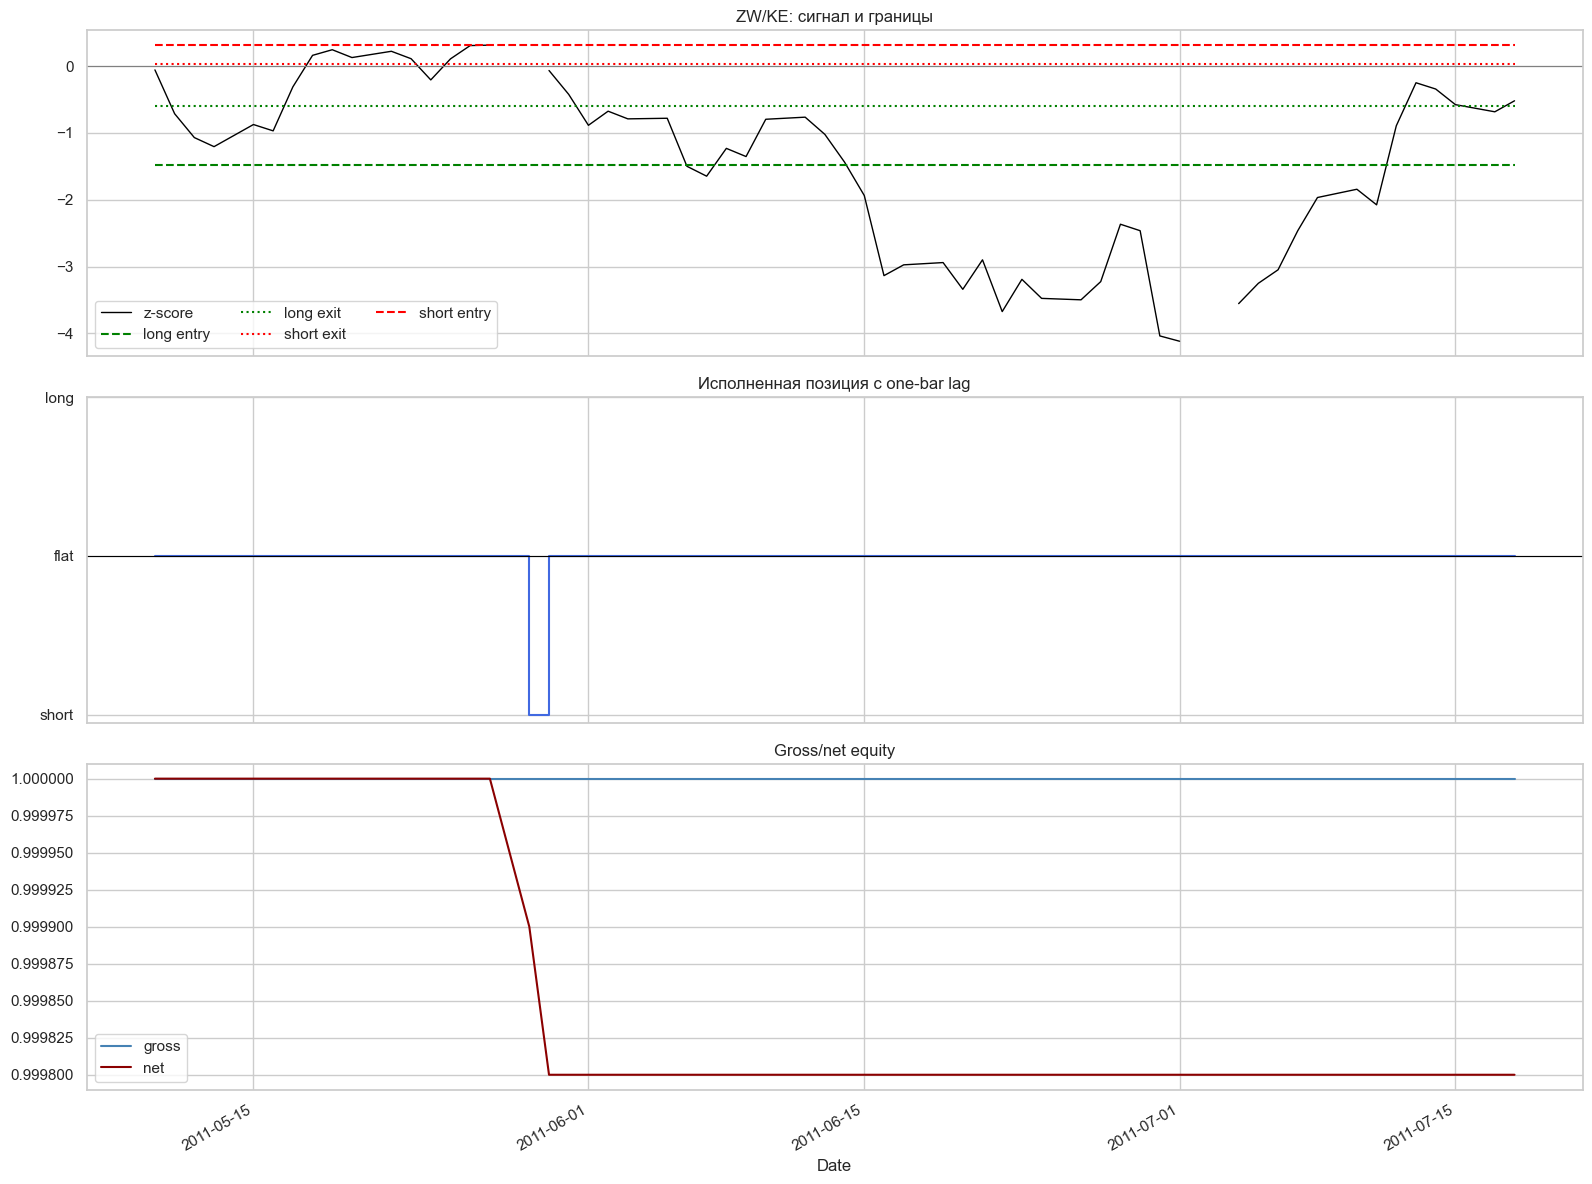

In [272]:
if selected_pairs:
    example_pair = selected_pairs[0]
    example_data = (
        pair_panel
        .xs(example_pair, level="pair")
        .sort_index()
    )

    fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

    example_data["z"].plot(
        ax=axes[0], color="black", linewidth=1.0, label="z-score"
    )
    example_data["long_entry"].plot(
        ax=axes[0], color="green", linestyle="--", label="long entry"
    )
    example_data["long_exit"].plot(
        ax=axes[0], color="green", linestyle=":", label="long exit"
    )
    example_data["short_exit"].plot(
        ax=axes[0], color="red", linestyle=":", label="short exit"
    )
    example_data["short_entry"].plot(
        ax=axes[0], color="red", linestyle="--", label="short entry"
    )
    axes[0].axhline(0.0, color="grey", linewidth=0.8)
    axes[0].set_title(f"{example_pair}: сигнал и границы")
    axes[0].legend(ncol=3)

    example_data["position"].plot(
        ax=axes[1], color="royalblue", drawstyle="steps-post"
    )
    axes[1].axhline(0.0, color="black", linewidth=0.8)
    axes[1].set_yticks([-1, 0, 1])
    axes[1].set_yticklabels(["short", "flat", "long"])
    axes[1].set_title("Исполненная позиция с one-bar lag")

    gross_equity = (1.0 + example_data["gross"].fillna(0.0)).cumprod()
    net_equity = (1.0 + example_data["net"].fillna(0.0)).cumprod()

    gross_equity.plot(ax=axes[2], color="steelblue", label="gross")
    net_equity.plot(ax=axes[2], color="darkred", label="net")
    axes[2].set_title("Gross/net equity")
    axes[2].legend()

    plt.tight_layout()
    plt.show()


## 4.2. Gross/net PnL отдельных пар


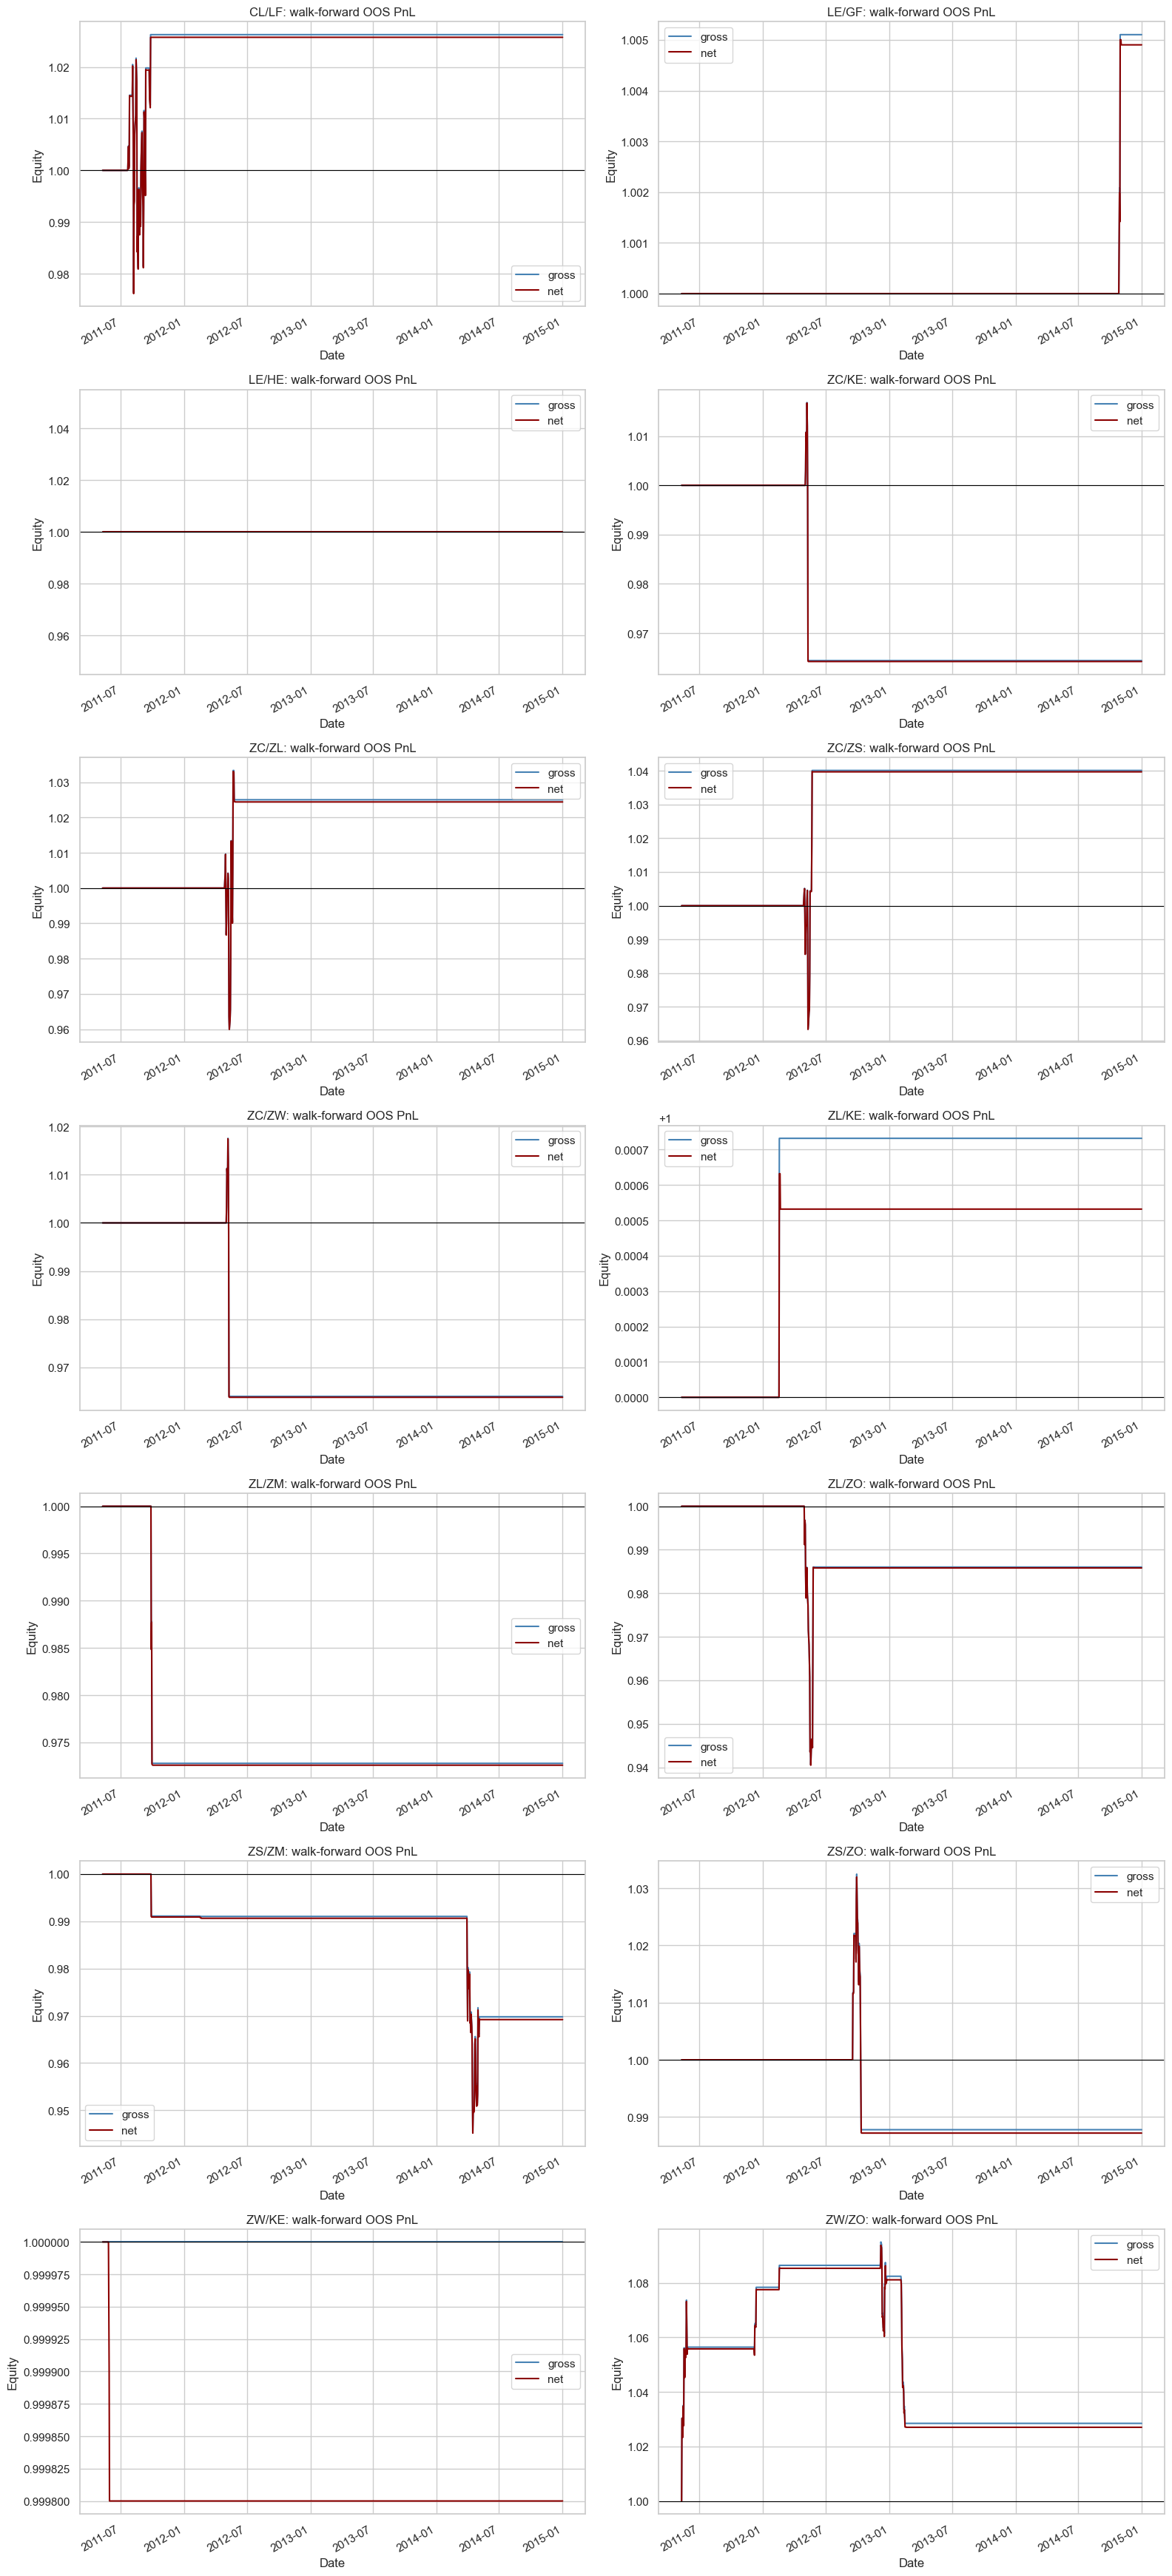

In [273]:
pair_gross_returns = (
    pair_panel["gross"]
    .unstack("pair")
    .sort_index()
    .fillna(0.0)
)

pair_net_returns = (
    pair_panel["net"]
    .unstack("pair")
    .reindex(pair_gross_returns.index)
    .fillna(0.0)
)

pairs_for_plot = pair_gross_returns.columns.tolist()
n_pairs = len(pairs_for_plot)

if n_pairs > 0:
    n_columns = 2
    n_rows = int(np.ceil(n_pairs / n_columns))

    fig, axes = plt.subplots(
        n_rows,
        n_columns,
        figsize=(16, 5 * n_rows),
        squeeze=False,
    )
    axes = axes.ravel()

    for ax, pair in zip(axes, pairs_for_plot):
        gross_equity = (1.0 + pair_gross_returns[pair]).cumprod()
        net_equity = (1.0 + pair_net_returns[pair]).cumprod()

        gross_equity.plot(ax=ax, color="steelblue", label="gross")
        net_equity.plot(ax=ax, color="darkred", label="net")
        ax.axhline(1.0, color="black", linewidth=0.8)
        ax.set_title(f"{pair}: walk-forward OOS PnL")
        ax.set_ylabel("Equity")
        ax.legend()

    for ax in axes[n_pairs:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


## 5. Нормирование риска и портфель

Портфель строится из OOS net-return серий:

1. Для каждой стратегии ex-ante volatility считается на прошлом окне и сдвигается на день.
2. Предварительный scale = target vol / realized vol, с ограничением плеча.
3. Риск сначала делится поровну между активными экономическими группами, затем внутри группы — между парами.
4. Вес отдельной стратегии и группы ограничен.
5. Итоговый портфель дополнительно масштабируется к общей цели по волатильности.

Так одна группа из 28 зерновых пар не получает в 28 раз больше риска, чем небольшая группа мяса.

In [274]:
net = pair_panel["net"].unstack("pair").fillna(0.0)
gross = pair_panel["gross"].unstack("pair").fillna(0.0).reindex(net.index)
pair_group = pair_panel.reset_index().drop_duplicates("pair").set_index("pair")["group"].to_dict()

ann_vol = net.rolling(CFG.vol_lookback, min_periods=30).std().shift(1) * np.sqrt(252)
vol_scale = (CFG.annual_target_vol / ann_vol).clip(upper=3.0).replace([np.inf, -np.inf], np.nan)
available_signal = net.ne(0).rolling(5, min_periods=1).max().astype(bool)

weights = pd.DataFrame(0.0, index=net.index, columns=net.columns)
groups = sorted(set(pair_group.values()))
for dt in weights.index:
    active_groups = []
    members_by_group = {}
    for g in groups:
        members = [p for p in net.columns if pair_group.get(p) == g and available_signal.at[dt, p] and np.isfinite(vol_scale.at[dt, p])]
        if members:
            active_groups.append(g)
            members_by_group[g] = members
    if not active_groups:
        continue
    group_budget = min(1.0 / len(active_groups), CFG.max_group_weight)
    for g in active_groups:
        members = members_by_group[g]
        raw = vol_scale.loc[dt, members].clip(lower=0.0)
        if raw.sum() > 0:
            w = group_budget * raw / raw.sum()
            weights.loc[dt, members] = w.clip(upper=CFG.max_strategy_weight)

pre_net = (weights * net).sum(axis=1)
pre_gross = (weights * gross).sum(axis=1)
book_vol = pre_net.rolling(CFG.vol_lookback, min_periods=30).std().shift(1) * np.sqrt(252)
book_scale = (CFG.annual_target_vol / book_vol).clip(upper=2.0).fillna(0.0)
weights = weights.mul(book_scale, axis=0)
portfolio_net_pre_kill = (weights * net).sum(axis=1)
portfolio_gross_pre_kill = (weights * gross).sum(axis=1)

print("Матрица OOS-доходностей:", net.shape)
print("Среднее число ненулевых весов:", weights.ne(0).sum(axis=1).mean().round(1))

Матрица OOS-доходностей: (778, 14)
Среднее число ненулевых весов: 0.4


## 6. Kill switch: логика и реализация

Kill switch не заменяет stop-loss. Stop ограничивает одну плохую сделку; kill switch реагирует на ситуацию, когда данным, модели, исполнению или всей книге больше нельзя доверять.

**Pair-level kill**:

- `|z| ≥ stop_z`: остаток ушёл в режим, который модель не описывает;
- отсутствуют/невалидны данные: позиция закрывается;
- max holding: позиция закрывается после `ceil(3 × half-life)` с границами 5–90 дней;
- после аварийного выхода — 10 дней cooldown.

**Book-level kill**:

- дневной loss хуже 2%;
- drawdown хуже 12%;
- доля доступных стратегий ниже 60% от недавней нормы;
- в live-коде сюда же должны входить stale quotes, рассинхронизация позиций broker vs model, rejected orders, превышение gross/net/commodity limit.

При срабатывании вес следующего дня равен нулю; затем 10 дней recovery. Автоматический полный рестарт запрещён: в production нужен ручной health-check. В учебном бэктесте после cooldown риск возвращается ступенчато.

In [275]:
def apply_book_kill(raw_returns: pd.Series, intended_weights: pd.DataFrame, data_coverage: pd.Series):
    live = True
    cooldown = 0
    ramp = 1.0
    equity = peak = 1.0
    out, flags, scales = [], [], []
    for dt, r in raw_returns.items():
        # Нулевые позиции могут быть нормальным отсутствием сигнала; data kill смотрит именно на входные цены.
        coverage_ok = data_coverage.loc[dt] >= CFG.min_active_fraction
        applied = float(r) * (ramp if live else 0.0)
        equity *= 1.0 + applied
        peak = max(peak, equity)
        dd = equity / peak - 1.0
        trigger = ""
        if live and (applied <= -CFG.book_daily_loss or dd <= -CFG.book_max_drawdown or not coverage_ok):
            trigger = "daily_loss" if applied <= -CFG.book_daily_loss else ("drawdown" if dd <= -CFG.book_max_drawdown else "coverage")
            live, cooldown, ramp = False, CFG.book_recovery_days, 0.0
        elif not live:
            cooldown -= 1
            if cooldown <= 0:
                live, ramp = True, 0.25
                peak = equity  # новая high-water mark после обязательного review
                trigger = "restart_25pct"
        elif ramp < 1.0:
            ramp = min(1.0, ramp + 0.25)
        out.append(applied)
        flags.append(trigger)
        scales.append(ramp if live else 0.0)
    return pd.DataFrame({"portfolio_net": out, "kill_event": flags, "next_risk_scale": scales}, index=raw_returns.index)

daily_data_coverage = log_price.notna().mean(axis=1).reindex(portfolio_net_pre_kill.index).fillna(0.0)
book = apply_book_kill(portfolio_net_pre_kill, weights, daily_data_coverage)
book["portfolio_gross"] = portfolio_gross_pre_kill * book["next_risk_scale"].shift(1).fillna(1.0)
book["equity"] = (1 + book["portfolio_net"]).cumprod()
book["drawdown"] = book["equity"] / book["equity"].cummax() - 1
book.query("kill_event != ''").tail(20)

,portfolio_net,kill_event,next_risk_scale,portfolio_gross,equity,drawdown
Date,,,,,,
2012-07-16,0.0,restart_25pct,0.25,0.0,0.993663,-0.012827
2012-09-02,0.0,coverage,0.00,0.0,0.993663,-0.012827
2012-09-13,0.0,restart_25pct,0.25,0.0,0.993663,-0.012827
2012-11-22,0.0,coverage,0.00,0.0,0.989046,-0.017414
2012-12-04,0.0,restart_25pct,0.25,0.0,0.989046,-0.017414
2012-12-25,0.0,coverage,0.00,0.0,0.987349,-0.019100
2013-01-06,0.0,restart_25pct,0.25,0.0,0.987349,-0.019100
2013-01-20,0.0,coverage,0.00,0.0,0.987349,-0.019100
2013-01-31,0.0,restart_25pct,0.25,0.0,0.987349,-0.019100


## 6.1. Суммарный gross/net PnL портфеля


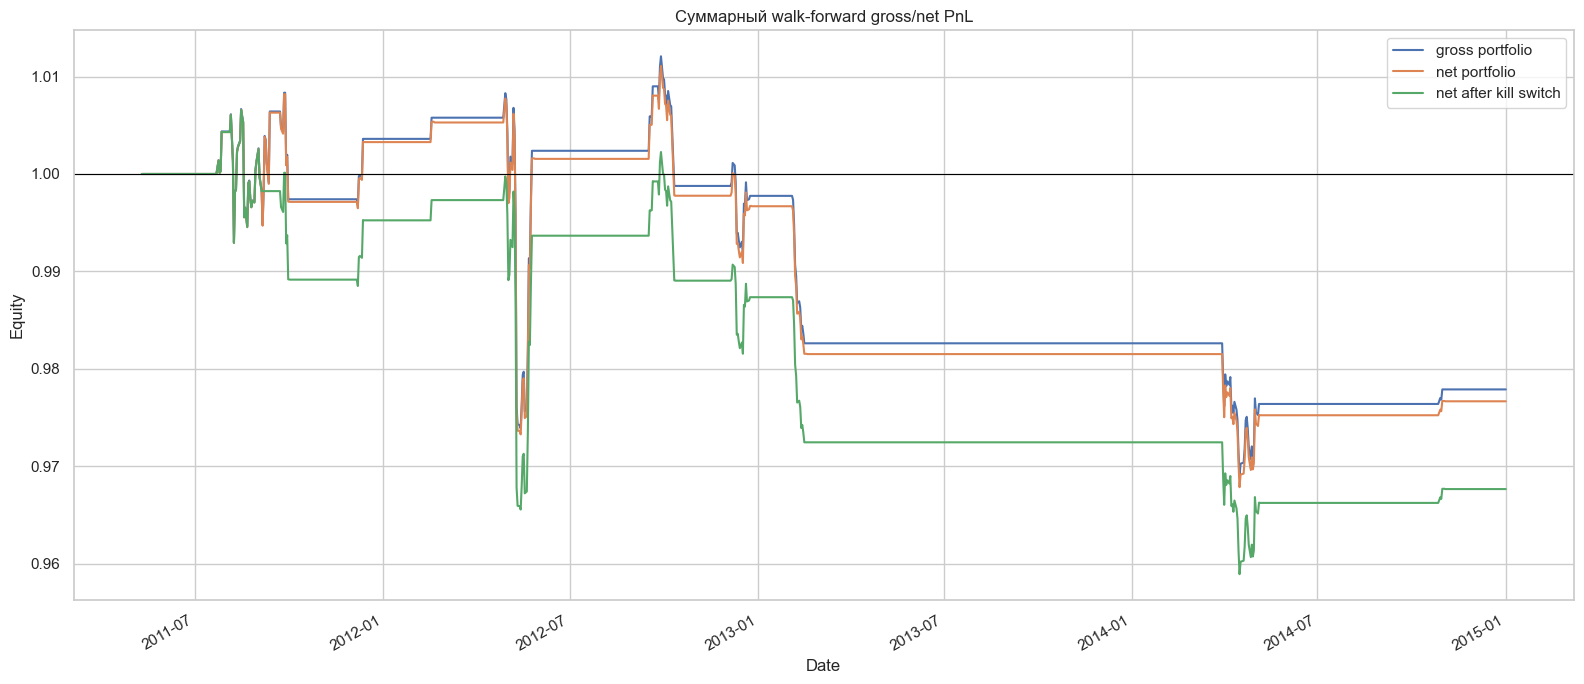

In [276]:
portfolio_equity = pd.DataFrame({
    "gross portfolio": (
        1.0 + portfolio_gross_pre_kill.fillna(0.0)
    ).cumprod(),
    "net portfolio": (
        1.0 + portfolio_net_pre_kill.fillna(0.0)
    ).cumprod(),
    "net after kill switch": (
        1.0 + book["portfolio_net"].fillna(0.0)
    ).cumprod(),
})

ax = portfolio_equity.plot(
    figsize=(16, 7),
    title="Суммарный walk-forward gross/net PnL",
)
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_ylabel("Equity")
ax.set_xlabel("Date")
plt.tight_layout()
plt.show()


## 7. Экспозиции базовых активов и неттинг затрат

Каждая pair-стратегия раскладывается на две нормированные dollar-exposure ноги. После умножения на портфельный вес все ноги суммируются по корневому товару. Именно здесь видны shared-leg concentration и взаимное погашение приказов.

В production target dollar exposure переводится в число контрактов как
`contracts = round(target_dollars / (Close × multiplier))`. После округления нужно повторно проверить gross/net/commodity limits.

In [277]:
def underlying_exposures(pair_panel, weights):
    rows = []
    flat = pair_panel.reset_index()
    for (dt, pair), r in flat.set_index(["Date", "pair"]).iterrows():
        if dt not in weights.index or pair not in weights.columns:
            continue
        w = weights.at[dt, pair]
        rows.append((dt, r["A"], w * r["leg_A"]))
        rows.append((dt, r["B"], w * r["leg_B"]))
    if not rows:
        return pd.DataFrame(index=weights.index)
    e = pd.DataFrame(rows, columns=["Date", "root", "exposure"]).groupby(["Date", "root"])["exposure"].sum().unstack(fill_value=0.0)
    return e.reindex(weights.index, fill_value=0.0)

underlying = underlying_exposures(pair_panel, weights)
exposure_diag = pd.DataFrame({
    "gross": underlying.abs().sum(axis=1),
    "net": underlying.sum(axis=1),
    "largest_commodity": underlying.abs().max(axis=1),
})
display(exposure_diag.describe(percentiles=[.5, .9, .95, .99]).T)

# Пример перевода последних целевых экспозиций в контракты для условного капитала.
CAPITAL = 1_000_000
last = underlying.index[-1]
contract_targets = []
for root, exp in underlying.loc[last].items():
    px = active_close.at[last, root] if root in active_close and last in active_close.index else np.nan
    mult = MULTIPLIER.get(root, np.nan)
    contracts = round(CAPITAL * exp / (px * mult)) if np.isfinite(px) and np.isfinite(mult) and px > 0 else np.nan
    contract_targets.append((root, exp, px, mult, contracts))
pd.DataFrame(contract_targets, columns=["root", "target_exposure", "close", "multiplier", "contracts"]).sort_values("target_exposure")

,count,mean,std,min,50%,90%,95%,99%,max
gross,778.0,0.070816,0.152178,0.000000,0.0,0.300000,0.300000,0.724465,0.800000
net,778.0,0.005907,0.066448,-0.162848,0.0,0.025692,0.079751,0.331830,0.470061
largest_commodity,778.0,0.042952,0.092956,0.000000,0.0,0.189875,0.231424,0.401910,0.531014


,root,target_exposure,close,multiplier,contracts
0,CL,0.0,53.91,1000,0.0
1,GF,0.0,NaN,500,NaN
2,HE,0.0,NaN,400,NaN
3,KE,0.0,NaN,50,NaN
4,LE,0.0,NaN,400,NaN
5,LF,0.0,535.25,100,0.0
6,ZC,0.0,NaN,50,NaN
7,ZL,0.0,NaN,600,NaN
8,ZM,0.0,NaN,100,NaN
9,ZO,0.0,NaN,50,NaN


## 8. Результаты: до/после costs, корреляции и концентрация

,CAGR,Ann.Vol,Sharpe,MaxDD,HitRate(days),BestDay,WorstDay
portfolio gross,-0.72%,2.34%,-29.78%,-4.26%,9.38%,0.96%,-1.98%
portfolio net before book kill,-0.76%,2.34%,-31.50%,-4.28%,9.38%,0.96%,-1.98%
portfolio net after book kill,-1.06%,2.25%,-46.21%,-4.74%,9.00%,0.96%,-1.98%


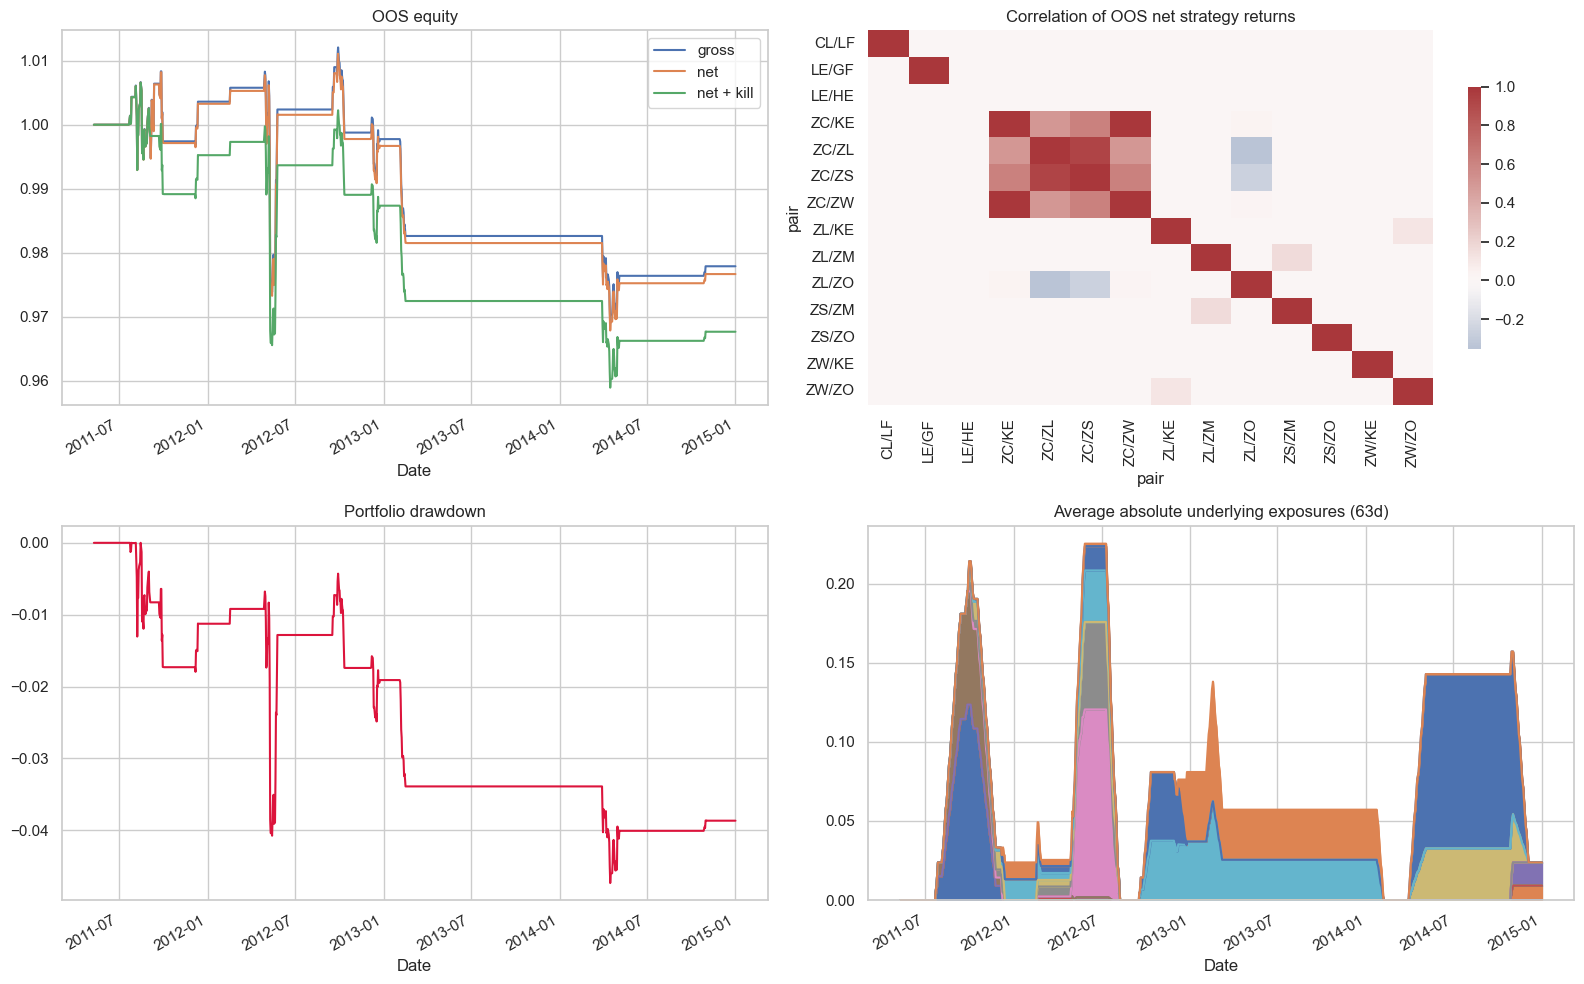

In [278]:
def performance(r: pd.Series, name: str) -> pd.Series:
    r = r.fillna(0.0)
    eq = (1 + r).cumprod()
    dd = eq / eq.cummax() - 1
    vol = r.std() * np.sqrt(252)
    return pd.Series({
        "CAGR": eq.iloc[-1] ** (252 / max(len(r), 1)) - 1,
        "Ann.Vol": vol,
        "Sharpe": (r.mean() * 252 / vol) if vol > 0 else np.nan,
        "MaxDD": dd.min(),
        "HitRate(days)": (r > 0).mean(),
        "BestDay": r.max(), "WorstDay": r.min(),
    }, name=name)

summary = pd.concat([
    performance(portfolio_gross_pre_kill, "portfolio gross"),
    performance(portfolio_net_pre_kill, "portfolio net before book kill"),
    performance(book["portfolio_net"], "portfolio net after book kill"),
], axis=1).T
display(summary.style.format("{:.2%}"))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
(1 + pd.DataFrame({"gross": portfolio_gross_pre_kill, "net": portfolio_net_pre_kill,
                   "net + kill": book["portfolio_net"]})).cumprod().plot(ax=axes[0, 0], title="OOS equity")
book["drawdown"].plot(ax=axes[1, 0], color="crimson", title="Portfolio drawdown")
sns.heatmap(net.corr().fillna(0), cmap="vlag", center=0, ax=axes[0, 1], cbar_kws={"shrink": .7})
axes[0, 1].set_title("Correlation of OOS net strategy returns")
underlying.abs().rolling(63).mean().plot.area(ax=axes[1, 1], title="Average absolute underlying exposures (63d)", legend=False)
plt.tight_layout()
plt.show()

In [279]:
pair_stats = pd.concat({p: performance(net[p], p) for p in net}, axis=1).T
pair_stats["group"] = pair_stats.index.map(pair_group)
pair_stats["OOS_days_active"] = net.ne(0).sum()
pair_stats.sort_values("Sharpe", ascending=False).head(25)

,CAGR,Ann.Vol,Sharpe,MaxDD,HitRate(days),BestDay,WorstDay,group,OOS_days_active
LE/GF,0.001585,0.002213,0.716767,-0.000566,0.003856,0.003583,-0.000566,meat,5
ZL/KE,0.000172,0.000364,0.473100,-0.000100,0.001285,0.000632,-0.000100,grains,2
ZC/ZS,0.012692,0.029752,0.438762,-0.041515,0.017995,0.025242,-0.029142,grains,20
ZW/ZO,0.008674,0.036619,0.253996,-0.061017,0.026992,0.030299,-0.017533,grains,53
ZC/ZL,0.007841,0.036372,0.232786,-0.049117,0.014139,0.033624,-0.027480,grains,24
CL/LF,0.008268,0.040497,0.223620,-0.043172,0.029563,0.024492,-0.032299,energy,43
ZL/ZO,-0.004615,0.023669,-0.183663,-0.059504,0.010283,0.021868,-0.017907,grains,24
ZS/ZO,-0.004171,0.016194,-0.250025,-0.043401,0.007712,0.011654,-0.009897,grains,20
ZS/ZM,-0.010081,0.022028,-0.448979,-0.054829,0.017995,0.018894,-0.012670,grains,35
ZC/ZW,-0.011877,0.022584,-0.517559,-0.052753,0.003856,0.008555,-0.034615,grains,8
